In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import Birch
import nltk
nltk.download('wordnet')
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from wordcloud import WordCloud
from sklearn.metrics import pairwise_distances
from collections import Counter

import gc #garbage collection

[nltk_data] Downloading package wordnet to /home/jack/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /home/jack/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


<h2>File reading</h2>

In [2]:
data = pd.read_csv("data_unsupervised.csv", encoding="utf8") #load data

#remove every character that is not a letter or a number
data['body'] = data['body'].str.replace(r'[^a-zA-Z0-9\s]', '', regex=True)
data['body'] = data['body'].str.lower() #convert to lowercase

data = data.drop_duplicates()#drop duplicates
data = data.dropna() #drop empty rows

#lemmatize data
lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

KeyboardInterrupt: 

In [ ]:
word_counts = data['body'].str.split().explode().value_counts()
#remove_words = set(word_counts[word_counts < 100].index)#removing words that appear less than 100 times in the dataset
remove_words = set(word_counts.nlargest(100).index)#removing the 100 most frequent words (stopwords)

def remove_selected_words(text):
    return ' '.join([word for word in text.split() if word not in remove_words])

most_frequent_words = set(word_counts.nlargest(140000).index)

def keep_most_frequent_words(text):
    return ' '.join([word for word in text.split() if word in most_frequent_words])

data['body'] = data['body'].apply(keep_most_frequent_words)

data['body'] = data['body'].apply(remove_selected_words)

data['body'] = data['body'].str.strip() #remove leading and trailing whitespace
data = data[~(data['body'] == '')] #drop empty comments

In [ ]:
data['word_count'] = data['body'].str.split().apply(len)
data = data[data['word_count'] >= 10] #keep comments with at least 10 words
data = data[data['word_count'] <= 500] #keep comments with at most 500 words

In [ ]:
vectorizer = CountVectorizer()
#vectorizer = TfidfVectorizer()
vectorizedData = vectorizer.fit_transform(data['body'])

<h2>Determining the number of clusters</h2>

In [ ]:
# Parameter grids
thresholds = [0.0005,0.001, 0.05, 0.3]
branching_factors = [15, 25, 50, 75]
best_score = -1
best_params = None

test_set = vectorizedData[:5000]

for t in thresholds:
    for bf in branching_factors:
        print("Testing parameters: threshold={}, branching_factor={}".format(t, bf))
        birch = Birch(threshold=t, branching_factor=bf, n_clusters=7, compute_labels=True)
        birch.fit(test_set)
        labels = birch.labels_
        del birch
        gc.collect()

        try:
            score = silhouette_score(
                test_set,
                labels,
            )
            if score > best_score:
                best_score = score
                best_params = {
                    'threshold': t,
                    'branching_factor': bf,
                }
        except:
            # If silhouette_score raises ValueError, it means there's only one cluster in the sample choosen
            continue
        # Clean up memory after each model
        del labels
        gc.collect()
print("Best score:", best_score)
print("Best parameters:", best_params)

Testing parameters: threshold=0.0005, branching_factor=15
Testing parameters: threshold=0.0005, branching_factor=25
Testing parameters: threshold=0.0005, branching_factor=50
Testing parameters: threshold=0.0005, branching_factor=75
Testing parameters: threshold=0.001, branching_factor=15
Testing parameters: threshold=0.001, branching_factor=25
Testing parameters: threshold=0.001, branching_factor=50
Testing parameters: threshold=0.001, branching_factor=75
Testing parameters: threshold=0.05, branching_factor=15
Testing parameters: threshold=0.05, branching_factor=25
Testing parameters: threshold=0.05, branching_factor=50
Testing parameters: threshold=0.05, branching_factor=75
Testing parameters: threshold=0.3, branching_factor=15
Testing parameters: threshold=0.3, branching_factor=25
Testing parameters: threshold=0.3, branching_factor=50
Testing parameters: threshold=0.3, branching_factor=75
Best score: 0.009868861578192573
Best parameters: {'threshold': 0.3, 'branching_factor': 75}


In [ ]:
n_clusters_options = range(3,10,1)  #n_clusters_options = None means no final clustering step
n_clusters_options=[5]
silhouette_scores = []
errors=[]
for nc in n_clusters_options:
    birch = Birch(**best_params, n_clusters=nc)
    labels = birch.fit_predict(vectorizedData)
    centroid_matrix = birch.subcluster_centers_[labels]
    del birch
    gc.collect()

    try:
        silhouette_scores.append(silhouette_score(
            vectorizedData,
            labels,
            sample_size=100000
        ))
        distances = pairwise_distances(vectorizedData, centroid_matrix, metric='euclidean')
        errors.append(np.sum(distances ** 2))    
    except ValueError:
        # If silhouette_score raises ValueError, it means there's only one cluster in the sample choosen
        continue
    # Clean up memory after each model
    del labels, centroid_matrix, distances
    gc.collect()

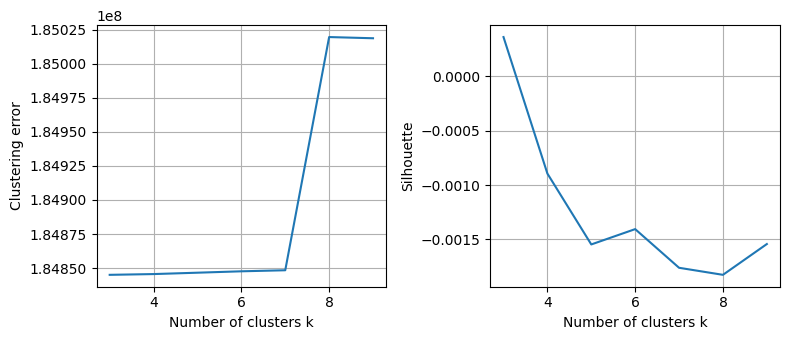

In [ ]:
fig, axs = plt.subplots(1,2, figsize=(8, 3.5))

axs[0].plot(
    [k for k in n_clusters_options], 
    [error for error in errors]
)
axs[0].set_xlabel("Number of clusters k")
axs[0].set_ylabel("Clustering error")
axs[0].grid()

axs[1].plot(
    [k for k in n_clusters_options], 
    [s for s in silhouette_scores]
)
axs[1].set_xlabel("Number of clusters k")
axs[1].set_ylabel("Silhouette")#Compute the mean Silhouette Coefficient of all samples.
axs[1].grid()

plt.tight_layout()
plt.show()

In [ ]:
numberOfChoosenClusters=3
indexOfChoosenCluster = n_clusters_options[n_clusters_options == numberOfChoosenClusters]
best_birch = Birch(**best_params,n_clusters=numberOfChoosenClusters)
best_birch.fit(vectorizedData)

,threshold,0.3
,branching_factor,50
,n_clusters,7
,compute_labels,True
,copy,'deprecated'


<h2>User Distribution Analysis</h2>

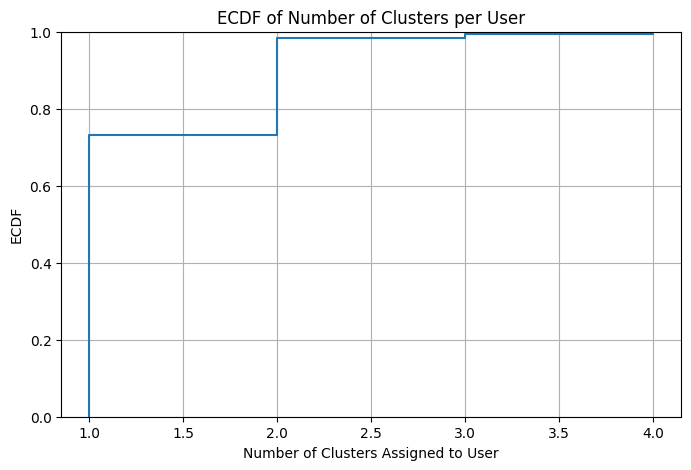

In [34]:
data["cluster"]= best_birch.labels_
user_clusters = data.groupby('author')['cluster'].nunique().reset_index()#grouping by author
#user clusters is now a series with author and number of clusters
user_clusters.columns = ['author', 'num_clusters']#turn it into a DF

# Filter user_clusters to only those authors who have multiple comments
authors_with_multiple_comments = data.groupby('author')['body'].nunique()
authors_with_multiple_comments = authors_with_multiple_comments[authors_with_multiple_comments > 1].index
user_clusters = user_clusters[user_clusters['author'].isin(authors_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=user_clusters, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to User')
plt.ylabel('ECDF')
plt.title('ECDF of Number of Clusters per User')
plt.grid(True)
plt.show()

In [35]:
PCA_number_components=1000
PCA_number_components=500
pca=PCA(n_components=PCA_number_components,random_state=42,)
pca=pca.fit(vectorizedData[:100000])
X_pca=pca.transform(vectorizedData)


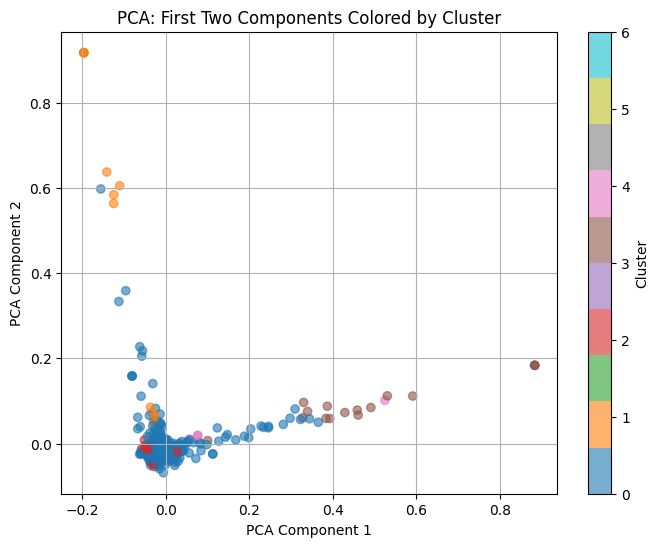

In [36]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=data['cluster'], cmap='tab10', alpha=0.6)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('PCA: First Two Components Colored by Cluster')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

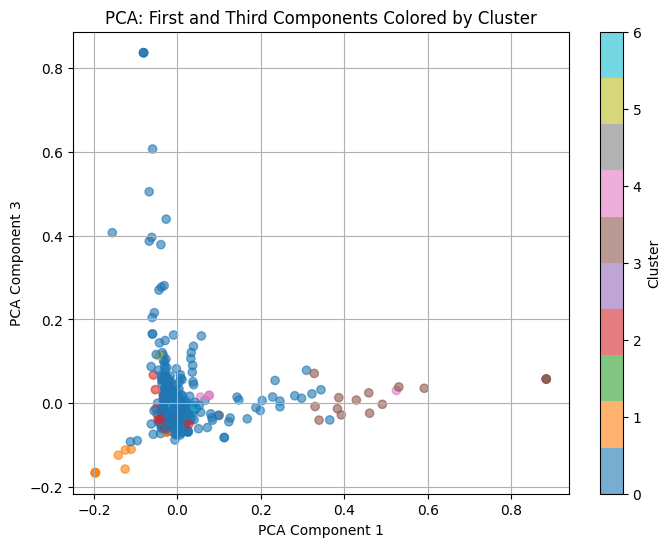

In [37]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 2], c=data['cluster'], cmap='tab10', alpha=0.6)
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 3')
plt.title('PCA: First and Third Components Colored by Cluster')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

<h3>Cluster analysis</h3>

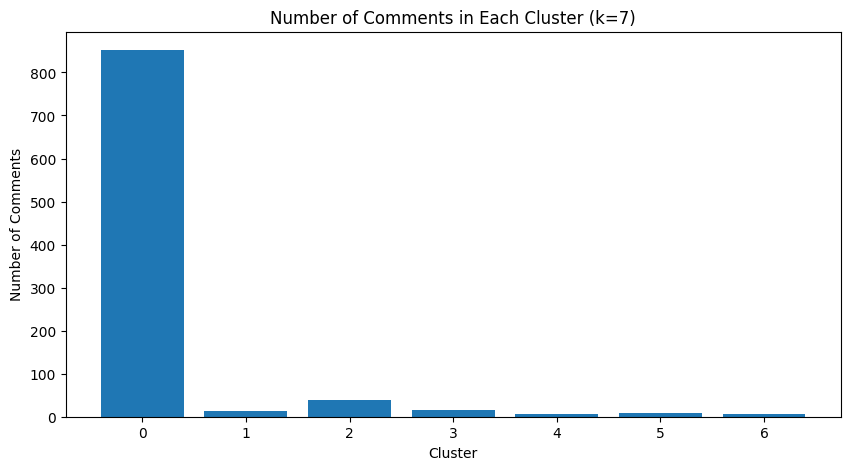

Cluster sizes: 0    852
2     40
3     16
1     13
5      9
4      7
6      6
Name: count, dtype: int64


In [38]:
#Plot the number of comments for each cluster
cluster_sizes = pd.Series(best_birch.labels_).value_counts()
plt.figure(figsize=(10, 5))
plt.bar(cluster_sizes.index, cluster_sizes.values)
plt.title(f"Number of Comments in Each Cluster (k={numberOfChoosenClusters})")
plt.xlabel("Cluster")
plt.ylabel("Number of Comments")
plt.xticks(cluster_sizes.index)
plt.show()
print("Cluster sizes:", cluster_sizes)

In [39]:
!pip install WordCloud

7369.37s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


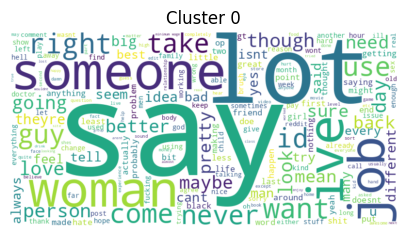

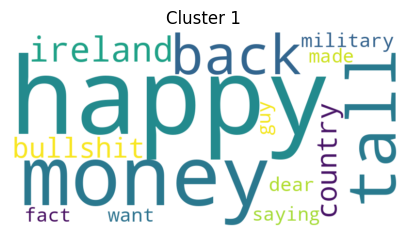

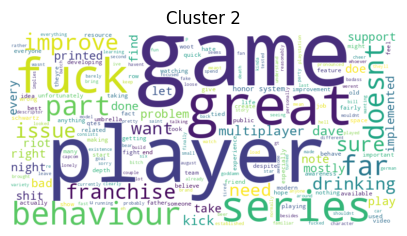

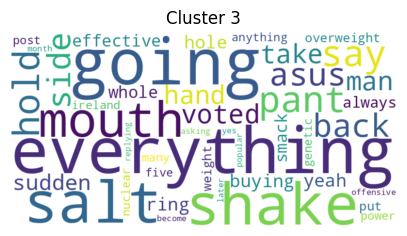

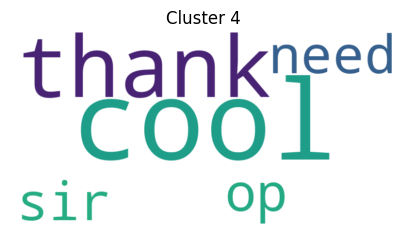

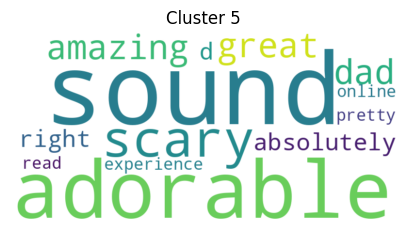

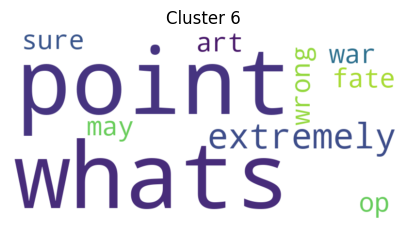

In [40]:
texts_dict = {}
# Prepare texts for each cluster
for i in range(0, numberOfChoosenClusters):
    texts_dict[i] = " ".join(data[data['cluster'] == i]['body'].values)

# Generate and display word clouds for each cluster
for i in range(0, numberOfChoosenClusters):
    if cluster_sizes[i] > 5 and texts_dict[i]:
        wordcloud = WordCloud(width=800, height=400, background_color='white').generate(texts_dict[i])

        plt.figure(figsize=(5, 3))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')  
        plt.title(f"Cluster {i}")
        plt.show()
    else:
        print(f"Cluster {i} is too small to display, printing each comment instead:")
        for _, comment in data[data['cluster'] == i].iterrows():
            print(f"author: {comment['author']}, subreddit: {comment['subreddit']}, body: {comment['body']}")

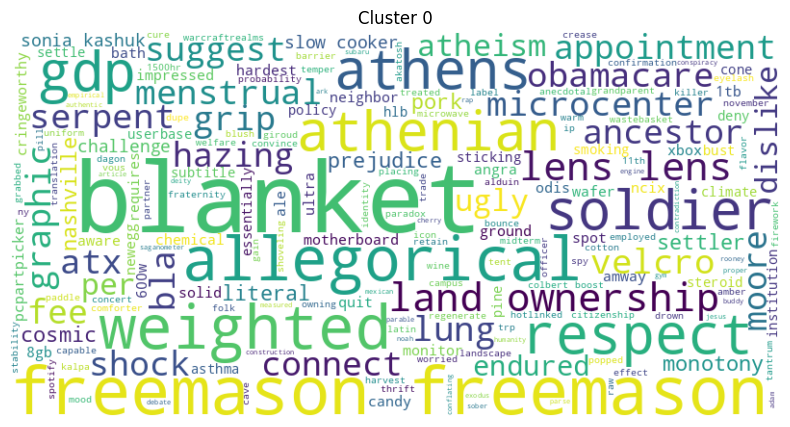

Error generating word cloud for cluster 1: We need at least 1 word to plot a word cloud, got 0.


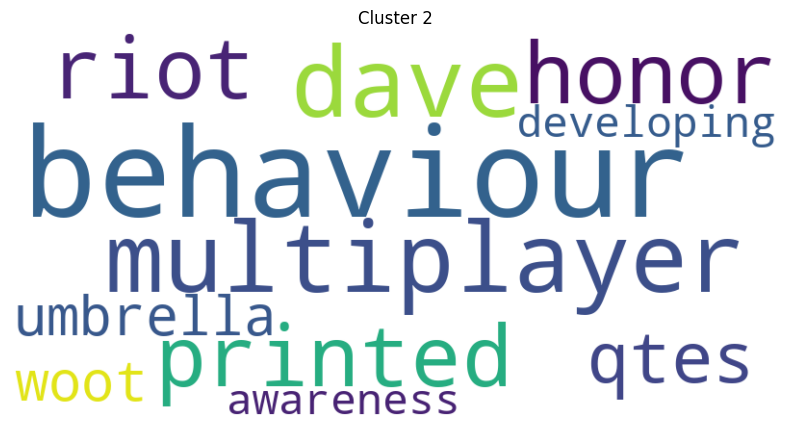

Error generating word cloud for cluster 3: We need at least 1 word to plot a word cloud, got 0.
Error generating word cloud for cluster 4: We need at least 1 word to plot a word cloud, got 0.
Error generating word cloud for cluster 5: We need at least 1 word to plot a word cloud, got 0.
Error generating word cloud for cluster 6: We need at least 1 word to plot a word cloud, got 0.


In [43]:
centroids = pd.DataFrame(
    best_birch.subcluster_centers_,
    columns= sorted(vectorizer.vocabulary_, key=vectorizer.vocabulary_.get)
)
# we want to only keep the features (columns) that have only one value different from 0
#meaning that we are only keeping the words that are present in one single cluster
listOfRelevantWords= centroids.loc[:, (centroids != 0).sum() == 1].dropna(axis=1).columns.tolist()
# Remove all words not in listOfRelevantWords from each string in texts
filtered_texts = []
relevant_set = set(listOfRelevantWords)
texts = list(texts_dict.values())
for t in texts:
    filtered = " ".join([w for w in t.split() if w in relevant_set])
    filtered_texts.append(filtered)

for i in range(0, numberOfChoosenClusters):
    try:
        if cluster_sizes[i] > 5:
            wordcloud = WordCloud(width=800, height=400, background_color='white').generate(filtered_texts[i])

            plt.figure(figsize=(10, 5))
            plt.imshow(wordcloud, interpolation='bilinear')
            plt.title(f"Cluster {i}")
            plt.axis('off')  
            plt.show()
        else:
            print(f"Cluster {i} is too small to display, printing each comment instead:")
            for _, comment in data[data['cluster'] == i].iterrows():
                print(comment['subreddit'])
    except Exception as e:
        print(f"Error generating word cloud for cluster {i}: {e}")

<h2>Subreddit distribution</h2>

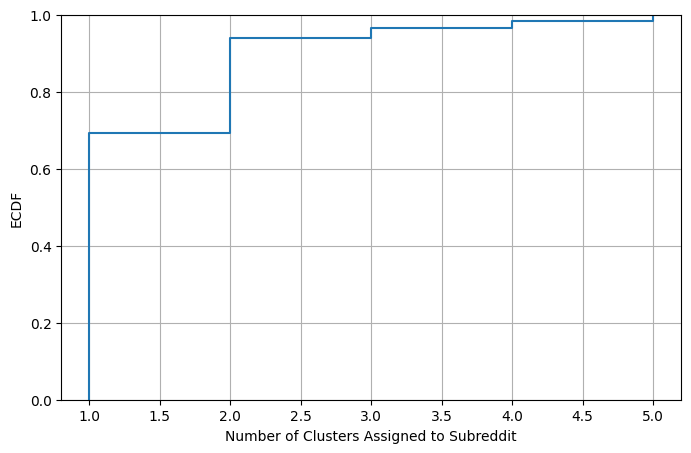

In [45]:
subreddit_cluster = data.groupby('subreddit')['cluster'].nunique().reset_index()#grouping by subreddit
#subreddit clusters is now a series with subreddit and number of clusters
subreddit_cluster.columns = ['subreddit', 'num_clusters']#turn it into a DF

# Filter subreddit_cluster to only those subreddits that have multiple comments
subreddits_with_multiple_comments = data.groupby('subreddit')['body'].nunique()
subreddits_with_multiple_comments = subreddits_with_multiple_comments[subreddits_with_multiple_comments > 1].index
subreddit_cluster = subreddit_cluster[subreddit_cluster['subreddit'].isin(subreddits_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=subreddit_cluster, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to Subreddit')
plt.ylabel('ECDF')
plt.grid(True)
plt.show()

Cluster 0 has 852 comments


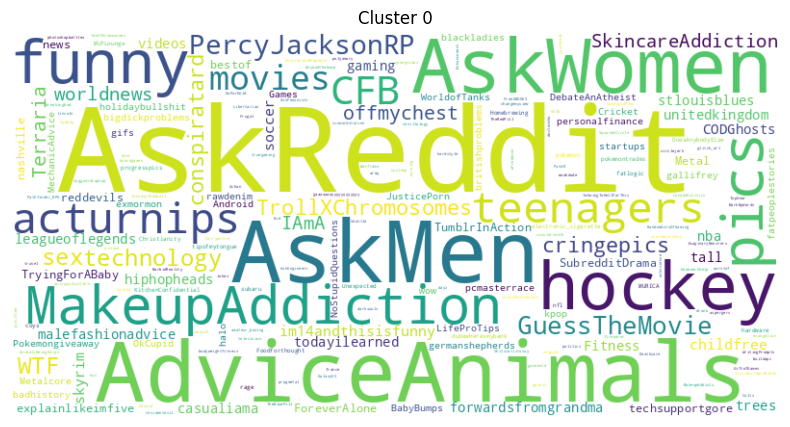

Cluster 1 has 13 comments


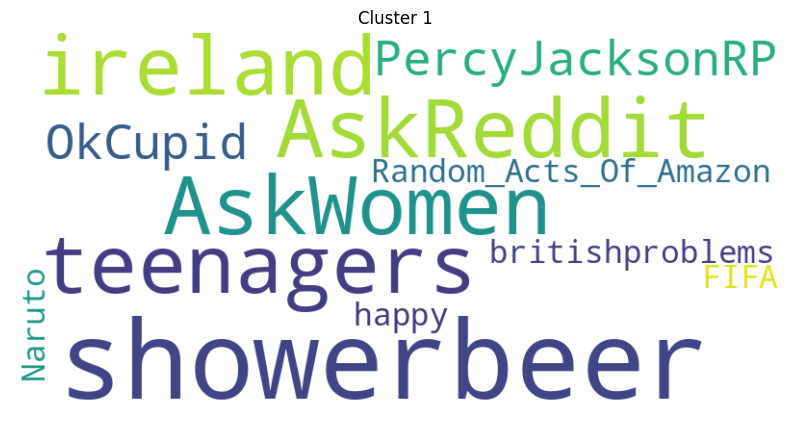

Cluster 2 has 40 comments


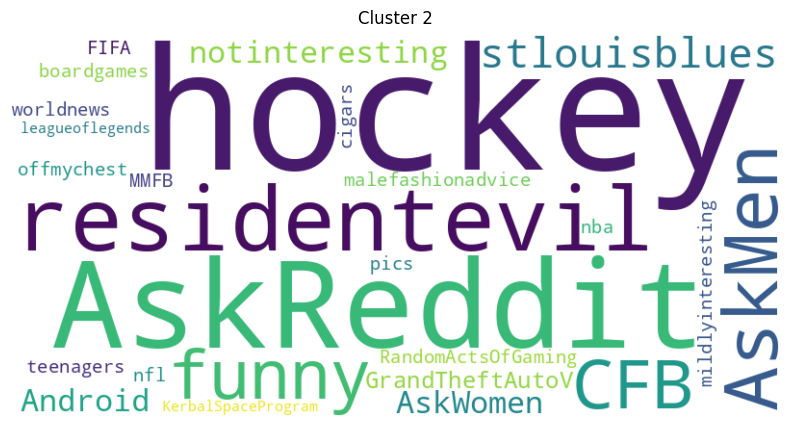

Cluster 3 has 16 comments


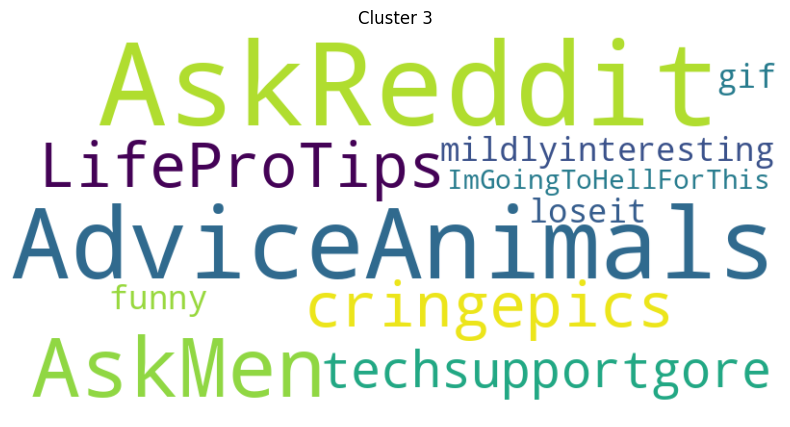

Cluster 4 has 7 comments


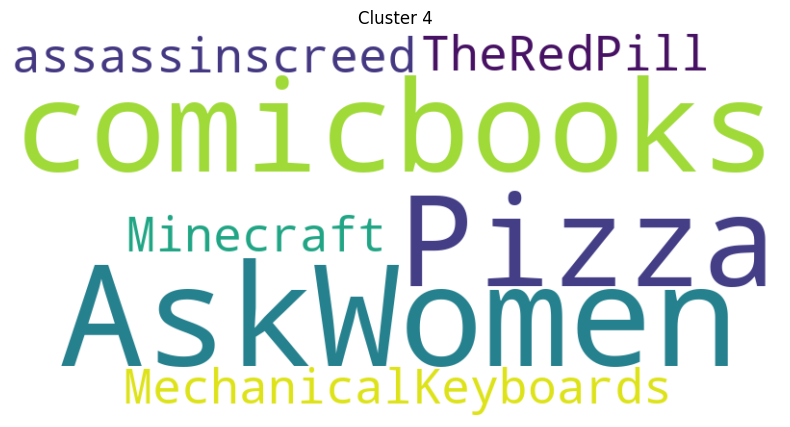

Cluster 5 has 9 comments


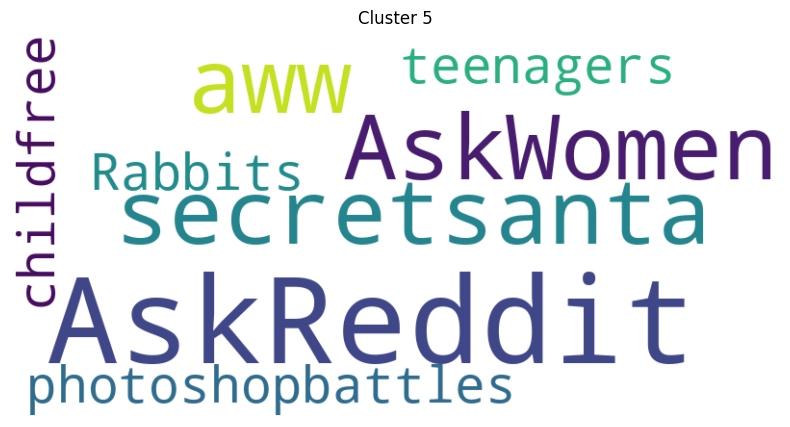

Cluster 6 has 6 comments


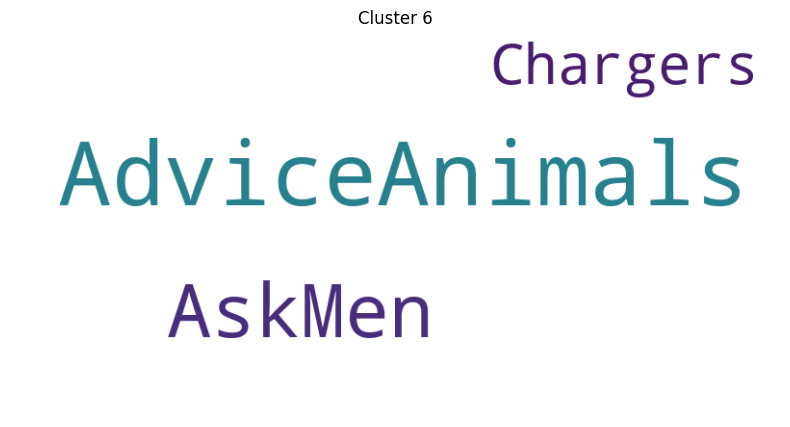

In [46]:
subredditsNames = []
for i in range(0, numberOfChoosenClusters):
    print(f"Cluster {i} has {cluster_sizes[i]} comments")
    subredditsNames.append(" ".join(data[data['cluster'] == i]['subreddit'].values))
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(subredditsNames[i])

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title(f"Cluster {i}")
    plt.show()